In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Dataset
from torch import nn
from torch import optim
import torch.nn.functional as F
import matplotlib.patches as patches
import seaborn as sns
from datetime import datetime
import cvae_module
import torchview

This notebook provides a short analysis and comparison of the results obtains after fitting the VAE and CVAE on a trajectory dataset.

## Pre-treatment of the data

In [2]:
# Treating the data
data_path = "~/Documents/maccoloc/maccoRoc/data/xgv/xgv_100_14-18.csv"
data = pd.read_csv(data_path)
data.head()

lgv = (-4.28, 47.78)

padding = 24

traj_all = np.zeros((len(data.maree.unique()), 2, padding))

i = 0
for tt in data.maree.unique():
    traj = data[data.maree == tt].copy()
    traj = traj.loc[:,('x','y')].to_numpy()

    n = traj.shape[0]
    traj_all[i, :, 0:n+1] = traj.T
    i+=1

month_id = np.zeros((len(data.maree.unique())))
day_id = np.zeros((len(data.maree.unique())))
i = 0
for tt in data.maree.unique():
    month_id[i] = data[data.maree == tt].month.iloc[1]
    day_id[i] = datetime.weekday(datetime.fromisoformat(data[data.maree == tt].time.iloc[0]))
    i+=1

traj_std = traj_all[day_id < 5,:,:].copy()

day = [datetime.strptime(data[data.maree == tt].time.iloc[1], '%Y-%m-%d').timetuple().tm_yday for tt in data.maree.unique()]
day = np.array(day)[day_id < 5]


# projection of coordinates in meters
R = 6377726 # earth radius
traj_std[:,0,:] = (np.pi * R * (traj_all[day_id < 5,0,:] + 4.28)/180)[:,:]
traj_std[:,1,:] = (np.pi * R * (traj_all[day_id < 5,1,:] - 47.78)/180)[:,:]

# standardization of (x,y) coordinates
scale = 10*1e4 # empirical choice
scale = traj_std.std()
traj_std = traj_std/scale

# Create dataloader

class TrajDataSet(Dataset):
    def __init__(self, traj, transform = None):
        self.traj = traj
        self.transform = transform
    
    def __len__(self):
        return self.traj.shape[0]

    def __getitem__(self, idx):
        # select coordinates
        sample = self.traj[idx,:,:]
        if self.transform:
            sample = self.transform(sample)
        return sample

class ToTensor(object):
    """Convert ndarrays in sample to Tensors"""
    def __call__(self, sample):
        return torch.FloatTensor(sample)

In [3]:
df_traj_std = pd.DataFrame(traj_std.transpose(0, 2, 1).reshape((traj_std.shape[0] * 24, 2)), 
                index = np.repeat(np.arange(1, (traj_std.shape[0] + 1)), 24),
                columns = ['x', 'y'])
#df_traj_std.to_csv("../R_workdlow/pydata/xgv_traj_std.csv")

In [4]:
maree_id = pd.DataFrame(index = range(len(data.maree.unique())), columns = ['maree',  'navire', 'month', 'time'])

i = 0
for tt in data.maree.unique():
    maree_id.maree[i] = tt
    maree_id.month[i] = data[data.maree == tt].month.iloc[1]
    maree_id.navire[i] = data[data.maree == tt].navire.iloc[1]
    maree_id.time[i] = data[data.maree == tt].time.iloc[1]
    i+=1
maree_id = maree_id[day_id<5]

In [5]:
device = 'cpu'
real = torch.tensor(traj_std[:, :, :], dtype=torch.float).to(device)

In [6]:
#import datetime
#day = [datetime.datetime.strptime(data[][data.maree == tt].time.iloc[1], '%Y-%m-%d').timetuple().tm_yday for tt in data.maree.unique()]

day_x = np.cos(np.divide(day,365.25)*2*np.pi)
day_y = np.sin(np.divide(day,365.25)*2*np.pi)
c_day = torch.concat([torch.tensor(day_x, dtype=torch.float)[:, None], torch.tensor(day_y, dtype=torch.float)[:, None]], dim = 1)[:, :, None]


## Loading and saving the results for each model

In [8]:
nz = 3
optimizer = 'adam'
niter = 1000

for nz in range(2,6):
#    Exporting CVAE latent space
    E = cvae_module.cdepthCNNEncoder(nz = nz, nc = 2).to(device)
    G = cvae_module.cCNNGenerator(nz = nz, nc = 2).to(device)
    G.load_state_dict(torch.load('%s/G%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
    G.eval()
    E.load_state_dict(torch.load('%s/E%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
    E.eval()

    with torch.no_grad():
        z, mu, logsig = E(real, c_day)
        x_hat = G(mu[:,:,None], c_day)
    pd.concat([maree_id.reset_index(), pd.DataFrame(mu.cpu().numpy() ), pd.DataFrame(logsig.cpu().numpy())], axis = 1).to_csv("../R_workflow/pydata/latentspace_cvae_10k_%d.csv" % (nz), header=True)
#    Exporting VAE latent space
    E = cvae_module.cdepthCNNEncoder(nz = nz, nc = 2).to(device)
    G = cvae_module.cCNNGenerator(nz = nz, nc = 2).to(device)
    G.load_state_dict(torch.load('%s/G%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
    G.eval()
    E.load_state_dict(torch.load('%s/E%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
    E.eval()
    with torch.no_grad():
        z, mu, logsig = E(real, c_day)
        x_hat = G(mu[:,:,None], c_day)
    pd.concat([maree_id.reset_index(), pd.DataFrame(mu.cpu().numpy() ), pd.DataFrame(logsig.cpu().numpy())], axis = 1).to_csv("../R_workflow/pydata/latentspace_vae_10k_%d.csv" % (nz), header=True)



In [9]:
# Some codes for analysis

In [10]:
# Fourier spectral density
import scipy.signal as sp

def get_periodogram(traj):
    periodogram_lon = []
    periodogram_lat = []

    for j in range(traj.shape[0]):
        lon = traj[j, 0, :]
        lat = traj[j, 1, :]
        x, lon = sp.periodogram(lon, scaling = 'spectrum', detrend = False)
        x, lat = sp.periodogram(lat, scaling = 'spectrum', detrend = False)

        periodogram_lon.append(lon)
        periodogram_lat.append(lat)

    return (x, np.mean(periodogram_lon, axis=0), np.mean(periodogram_lat, axis=0))


def coord2step(coord):
    step = np.sqrt(np.diff(coord[:,0,:])**2 + np.diff(coord[:,1,:])**2)
    step = np.append(np.zeros((coord.shape[0],1)), step, 1)
    direction = np.diff(np.arctan2(np.diff(coord[:,1,:]),np.diff(coord[:,0,:])))
    direction = np.append(np.zeros((coord.shape[0],2)), direction, 1)
    return np.stack([step*20, direction/2/np.pi], 1)

# Analysis with 3 dimensional latent space

### Loading the pytorch dictionnary and geting the reconstructed trajectory, latent representation, mod and variance

In [15]:
nz = 3
optimizer = 'adam'
niter = 1000
E = cvae_module.cdepthCNNEncoder(nz = nz, nc = 2).to(device)
G = cvae_module.cCNNGenerator(nz = nz, nc = 2).to(device)
G.load_state_dict(torch.load('%s/G%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
G.eval()
E.load_state_dict(torch.load('%s/E%d_cvae_std_10k_%s_epoch_%d.pth' % ("save", nz, optimizer, niter), map_location=torch.device(device)))
E.eval()
with torch.no_grad():
    z, mu, logsig = E(real, c_day)
    x_hat = G(mu[:,:,None], c_day)

In [16]:
E.eval()

cdepthCNNEncoder(
  (cnn): Sequential(
    (0): Conv1d(4, 8, kernel_size=(4,), stride=(2,), padding=(1,), bias=False)
    (1): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv1d(8, 32, kernel_size=(4,), stride=(2,), padding=(1,), bias=False)
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv1d(32, 128, kernel_size=(3,), stride=(2,), padding=(1,), bias=False)
    (7): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Conv1d(128, 3, kernel_size=(2,), stride=(1,), bias=False)
  )
)

### Plotting the simplified architecture of neural networks

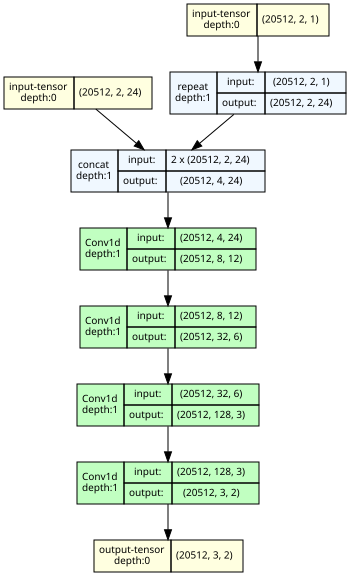

In [18]:
encoder_graph = torchview.draw_graph(cvae_module.graphcCNNEncoder(nz = 3, nc = 2), input_data = (real, c_day), 
                     graph_name = "CNN Encoder", depth = 1)
encoder_graph.visual_graph

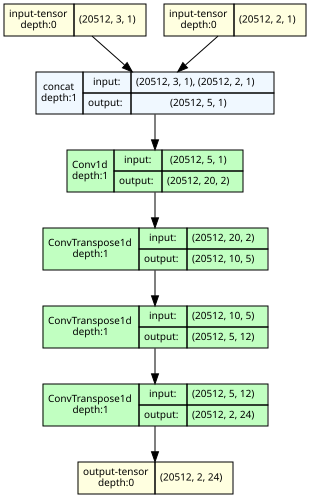

In [19]:
decoder_graph = torchview.draw_graph(cvae_module.graphcCNNGenerator(nz = 3, nc = 2).to(device), 
                                     input_data = (mu[:,:,None], c_day), 
                     graph_name = "CNN Decoder", depth = 1)
decoder_graph.visual_graph

In [21]:
### Simulating and plotting some random trajectories

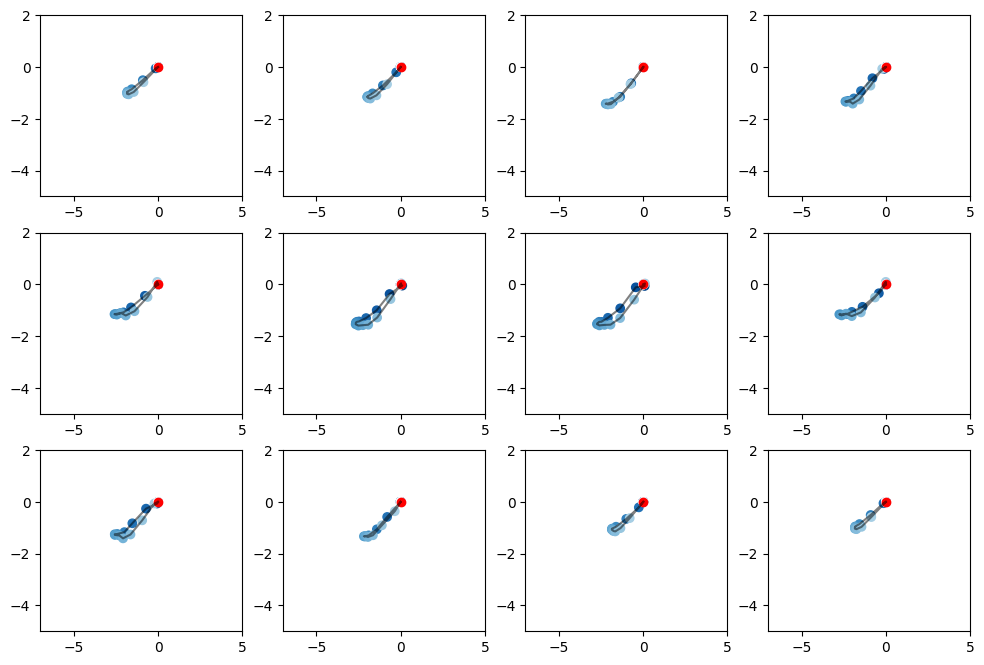

In [22]:
nb = 12
#z = torch.randn((nb, nz, 1), device = device)
c = torch.concat([torch.linspace(0,1, steps = nb).mul(2*torch.pi).cos().reshape(nb,1), \
                torch.linspace(0,1, steps = nb).mul(2*torch.pi).sin().reshape(nb,1)], dim = 1)[:, :, None]
c = c.to(device)
z = 0*torch.randn((nb, nz, 1), device = device)
with torch.no_grad():
    generated = G(z, c)
traj_sim = generated.cpu().detach().numpy()
plt.figure(figsize = (12,8))

for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r")
    plt.scatter(0, 0, c="red")
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)

plt.show()
plt.close()

### Position d'un bateau qui reste au port en fonction du mois (12 segments de 30 degré)

(-2.5, 2.5)

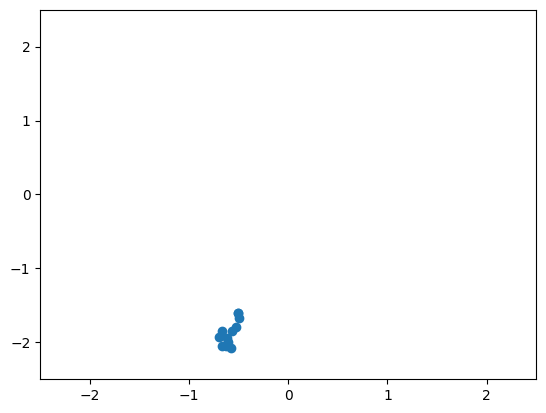

In [23]:
nb = 12
port = torch.tensor(0.).repeat(12, 2,24)
c = torch.concat([torch.linspace(0,1, steps = nb).mul(2*torch.pi).cos().reshape(nb,1), \
                torch.linspace(0,1, steps = nb).mul(2*torch.pi).sin().reshape(nb,1)], dim = 1)[:, :, None]
c = c.to(device)
_, mu_port, sig_port =E(port, c)
mu_port = mu_port.detach().numpy()
plt.scatter(mu_port[:,0], mu_port[:,2])
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5,2.5)


In [40]:
2*sig_port.exp().sqrt()

tensor([[0.2588, 1.8302, 1.1458],
        [0.2572, 1.8171, 1.1365],
        [0.2434, 1.7849, 1.1321],
        [0.2342, 1.7573, 1.1748],
        [0.2095, 1.7143, 1.1764],
        [0.1890, 1.6967, 1.1006],
        [0.1921, 1.7352, 1.1247],
        [0.2160, 1.8213, 1.2111],
        [0.2342, 1.9014, 1.1599],
        [0.2419, 1.8470, 1.1164],
        [0.2504, 1.8288, 1.1043],
        [0.2588, 1.8302, 1.1458]], grad_fn=<MulBackward0>)

### Trajectoire d'hiver

/home/saint-clair/miniconda3/lib/python3.9/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


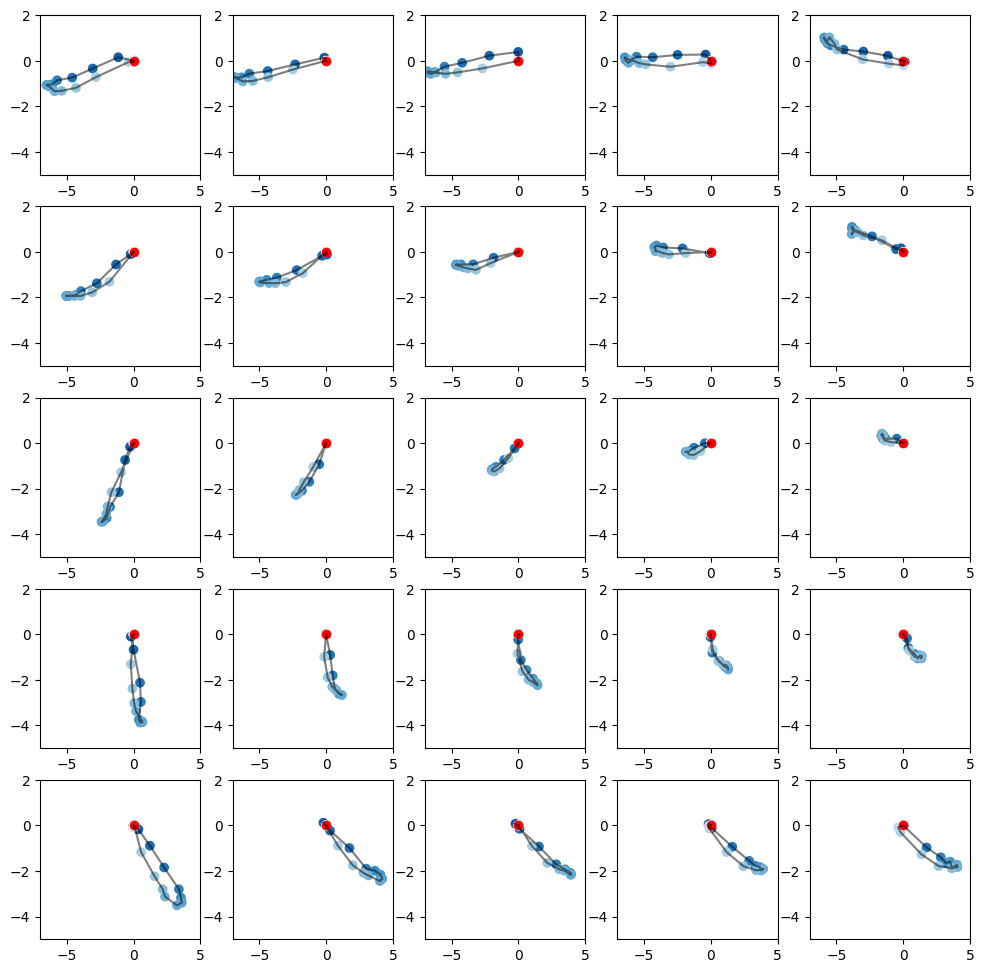

In [24]:
nb = 25
mu1, mu3 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(2,-2,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
c = torch.tensor([np.cos(.1*2*np.pi), np.sin(.1*2*np.pi)], dtype=torch.float32).repeat(25, 1).reshape(25, 2, 1)
c = c.to(device)
with torch.no_grad():
    generated = G(z, c)
traj_sim = generated.cpu().detach().numpy()
plt.figure(figsize = (12,12))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r")
    plt.scatter(0, 0, c="red")
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)

plt.show()
plt.close()

### Trajectoires de printemps

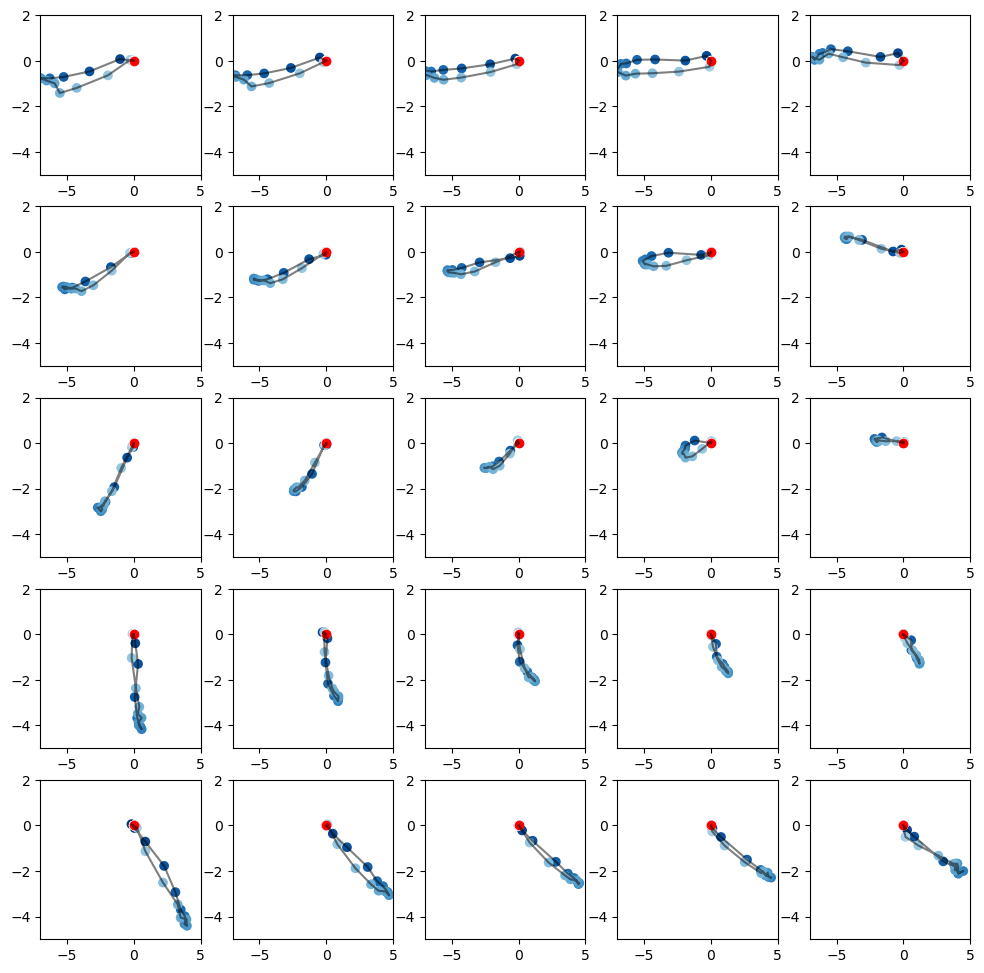

In [43]:
nb = 25
mu1, mu3 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(2,-2,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
c = torch.tensor([np.cos(.35*2*np.pi), np.sin(.35*2*np.pi)], dtype=torch.float32).repeat(25, 1).reshape(25, 2, 1)
c = c.to(device)
with torch.no_grad():
    generated = G(z, c)
traj_sim = generated.cpu().detach().numpy()
plt.figure(figsize = (12,12))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r")
    plt.scatter(0, 0, c="red")
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)

plt.show()
plt.close()

### Trajectoires d'été

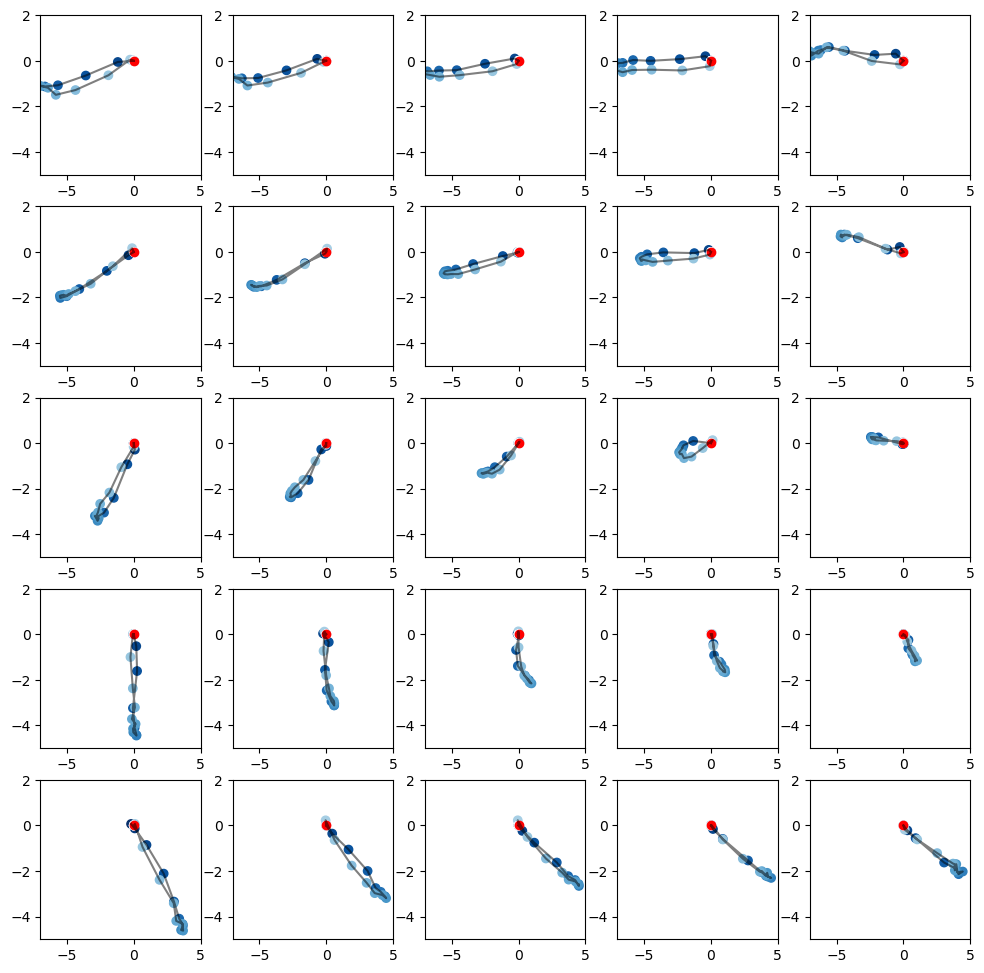

In [44]:
nb = 25
mu1, mu3 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(2,-2,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1),  mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
c = torch.tensor([np.cos(.6*2*np.pi), np.sin(.6*2*np.pi)], dtype=torch.float32).repeat(25, 1).reshape(25, 2, 1)
c = c.to(device)
with torch.no_grad():
    generated = G(z, c)
traj_sim = generated.cpu().detach().numpy()
plt.figure(figsize = (12,12))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r")
    plt.scatter(0, 0, c="red")
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)

plt.show()
plt.close()

### Trajectoire d'automne

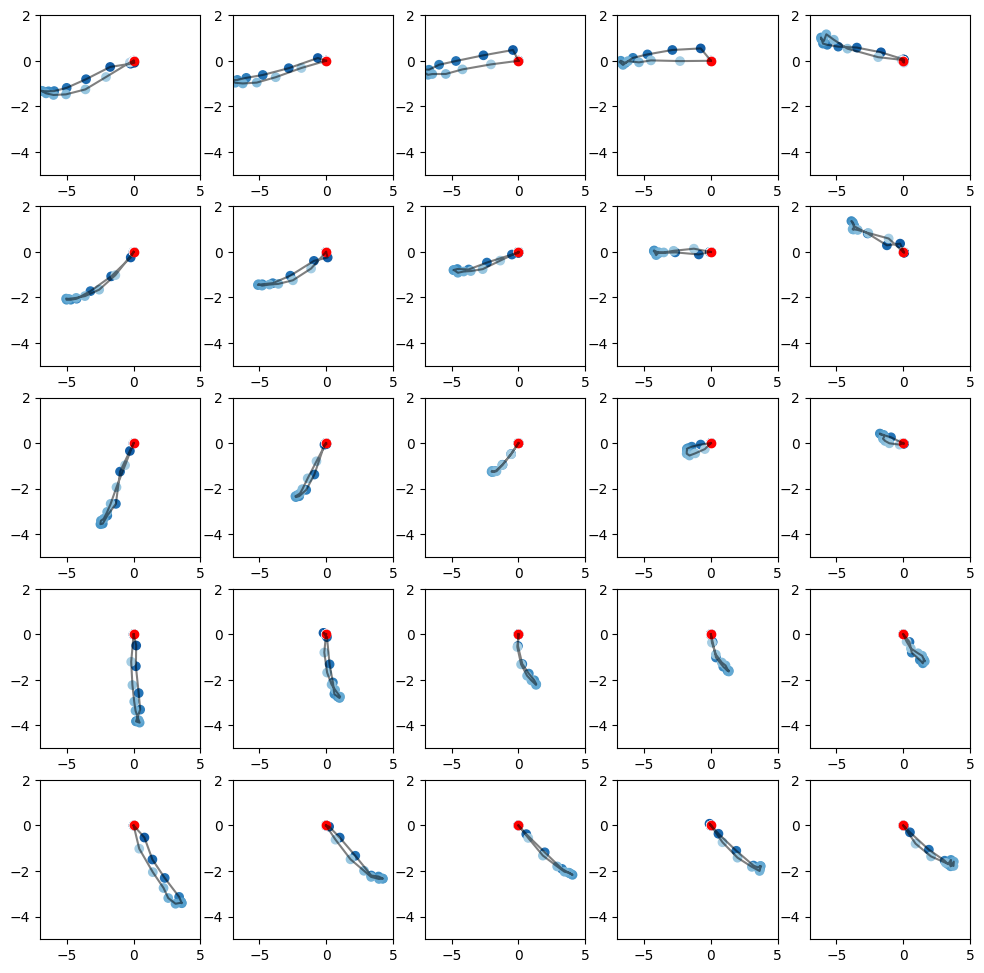

In [25]:
nb = 25
mu1, mu3 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(2,-2,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
c = torch.tensor([np.cos(.85*2*np.pi), np.sin(.85*2*np.pi)], dtype=torch.float32).repeat(25, 1).reshape(25, 2, 1)
c = c.to(device)
with torch.no_grad():
    generated = G(z, c)
traj_sim = generated.cpu().detach().numpy()
plt.figure(figsize = (12,12))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r")
    plt.scatter(0, 0, c="red")
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)

plt.show()
plt.close()

### Trajectoire hiver + été

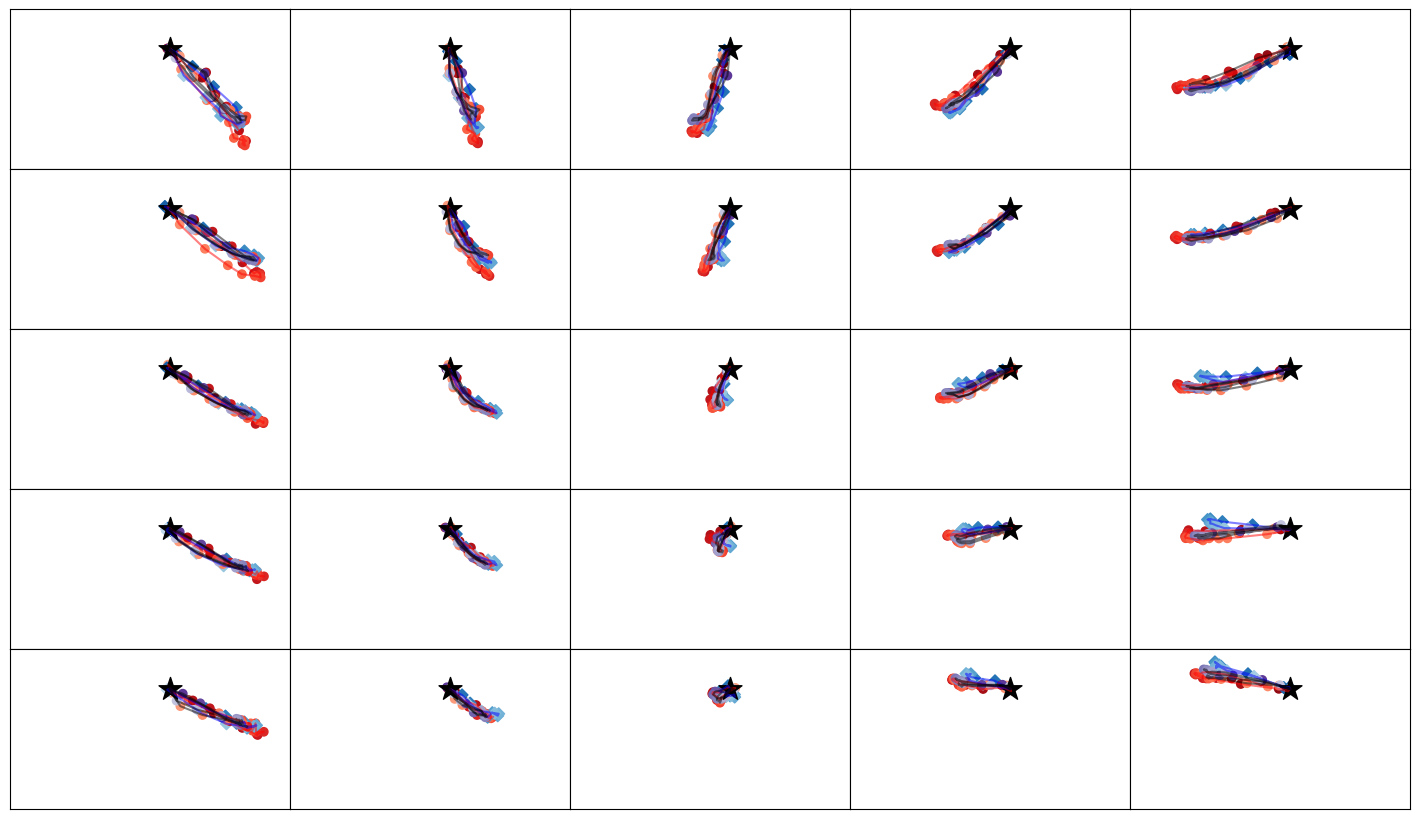

In [26]:
nb = 25
mu3, mu1 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(-2,1,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
cs = torch.tensor([np.cos(.5*2*np.pi), np.sin(.5*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cs = cs.to(device)
cw = torch.tensor([np.cos(.0*2*np.pi), np.sin(.0*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cw = cw.to(device)
cf = torch.tensor([np.cos(.75*2*np.pi), np.sin(.75*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cf = cf.to(device)
cp = torch.tensor([np.cos(.25*2*np.pi), np.sin(.25*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cp = cp.to(device)
with torch.no_grad():
    gs = G(z, cs)
    gw = G(z, cw)
    gf = G(z, cf)
    gp = G(z, cp)
traj_sim_sum = gs.cpu().detach().numpy()
traj_sim_win = gw.cpu().detach().numpy()
traj_sim_fal = gf.cpu().detach().numpy()
traj_sim_spr = gp.cpu().detach().numpy()
plt.figure(figsize = (14,8))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim_sum[i,0,:], traj_sim_sum[i,1,:], c="red", alpha=0.5)
    plt.plot(traj_sim_win[i,0,:], traj_sim_win[i,1,:], c="blue", alpha=0.5)
    plt.scatter(traj_sim_sum[i,0,:], traj_sim_sum[i,1,:], 
                c=np.arange(padding), cmap="Reds_r")
    plt.scatter(traj_sim_win[i,0,:], traj_sim_win[i,1,:], 
                c=np.arange(padding), cmap="Blues_r", marker = "D")
    plt.plot(traj_sim_spr[i,0,:], traj_sim_spr[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim_spr[i,0,:], traj_sim_spr[i,1,:], 
                c=np.arange(padding), cmap="Reds_r")
    plt.plot(traj_sim_fal[i,0,:], traj_sim_fal[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim_fal[i,0,:], traj_sim_fal[i,1,:], 
                c=np.arange(padding), cmap="Purples_r")
    plt.scatter(0, 0, c="black", marker = "*", s = 300)
    plt.axis('equal')
    plt.xlim(-8, 6)
    plt.ylim(-6, 2)
    plt.tick_params(axis='both', left=False, top=False, right=False, bottom=False, labelleft=False, labeltop=False, labelright=False, labelbottom=False)
plt.subplots_adjust(left=0,
                    bottom=0,
                    right=1,
                    top=1,
                    wspace=0,
                    hspace=0)
plt.show()
plt.close()

### 4 season plot

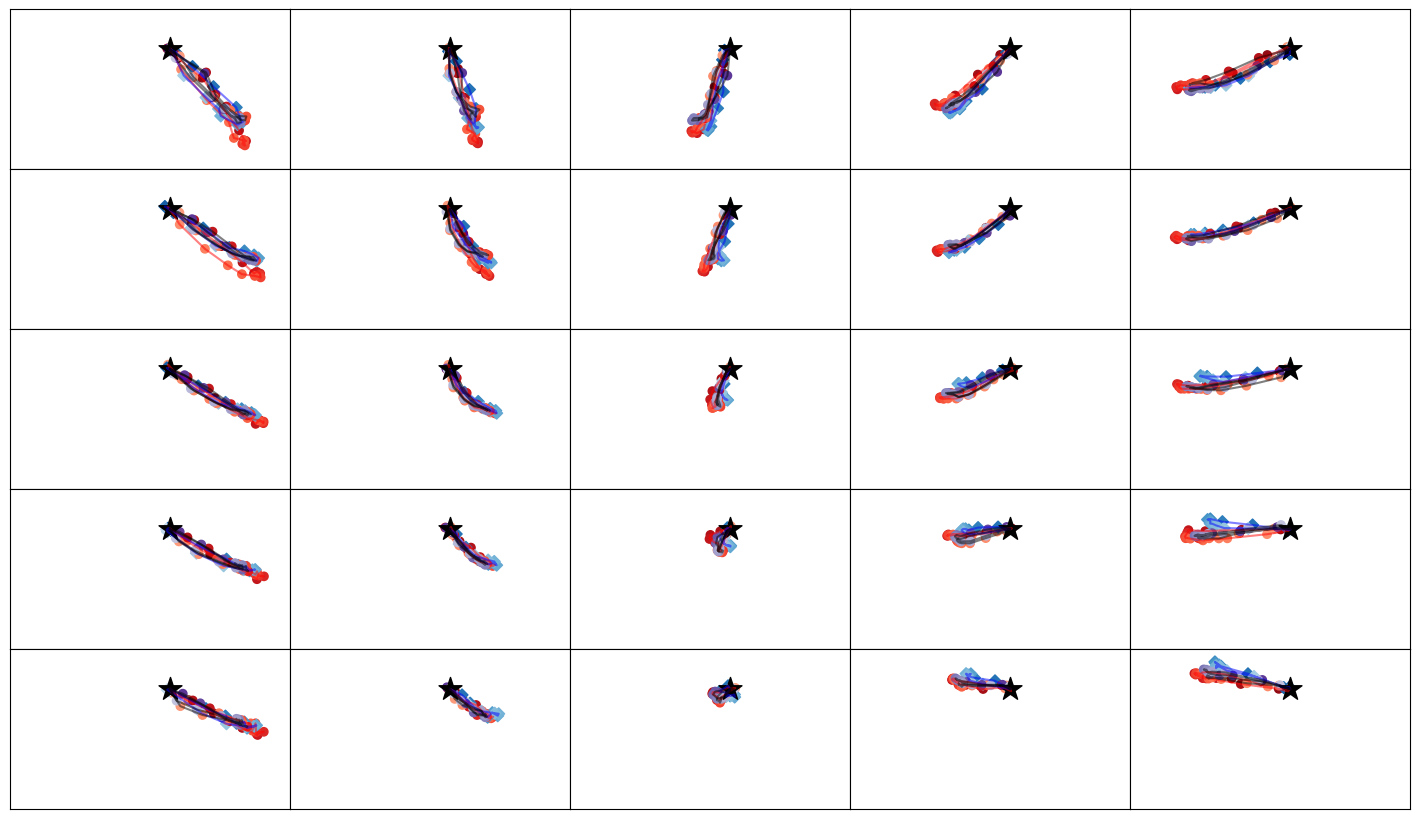

In [65]:
nb = 25
mu3, mu1 = torch.meshgrid(torch.linspace(2,-2,  steps = 5), torch.linspace(-2,1,  steps = 5))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).to(device)
cs = torch.tensor([np.cos(.5*2*np.pi), np.sin(.5*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cs = cs.to(device)
cw = torch.tensor([np.cos(.0*2*np.pi), np.sin(.0*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cw = cw.to(device)
cf = torch.tensor([np.cos(.75*2*np.pi), np.sin(.75*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cf = cf.to(device)
cp = torch.tensor([np.cos(.25*2*np.pi), np.sin(.25*2*np.pi)], dtype=torch.float32).repeat(nb, 1).reshape(nb, 2, 1)
cp = cp.to(device)
with torch.no_grad():
    gs = G(z, cs)
    gw = G(z, cw)
    gf = G(z, cf)
    gp = G(z, cp)
traj_sim_sum = gs.cpu().detach().numpy()
traj_sim_win = gw.cpu().detach().numpy()
traj_sim_fal = gf.cpu().detach().numpy()
traj_sim_spr = gp.cpu().detach().numpy()
plt.figure(figsize = (14,8))

for i in range(nb):
    plt.subplot(5, 5, i+1)
    plt.plot(traj_sim_sum[i,0,:], traj_sim_sum[i,1,:], c="red", alpha=0.5)
    plt.plot(traj_sim_win[i,0,:], traj_sim_win[i,1,:], c="blue", alpha=0.5)
    plt.scatter(traj_sim_sum[i,0,:], traj_sim_sum[i,1,:], 
                c=np.arange(padding), cmap="Reds_r")
    plt.scatter(traj_sim_win[i,0,:], traj_sim_win[i,1,:], 
                c=np.arange(padding), cmap="Blues_r", marker = "D")
    plt.plot(traj_sim_spr[i,0,:], traj_sim_spr[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim_spr[i,0,:], traj_sim_spr[i,1,:], 
                c=np.arange(padding), cmap="Reds_r")
    plt.plot(traj_sim_fal[i,0,:], traj_sim_fal[i,1,:], c="black", alpha=0.5)
    plt.scatter(traj_sim_fal[i,0,:], traj_sim_fal[i,1,:], 
                c=np.arange(padding), cmap="Purples_r")
    plt.scatter(0, 0, c="black", marker = "*", s = 300)
    plt.axis('equal')
    plt.xlim(-8, 6)
    plt.ylim(-6, 2)
    plt.tick_params(axis='both', left=False, top=False, right=False, bottom=False, labelleft=False, labeltop=False, labelright=False, labelbottom=False)
plt.subplots_adjust(left=0,
                    bottom=0,
                    right=1,
                    top=1,
                    wspace=0,
                    hspace=0)
plt.show()
plt.close()

### Plotting a lot of trajectories and their reconstructions

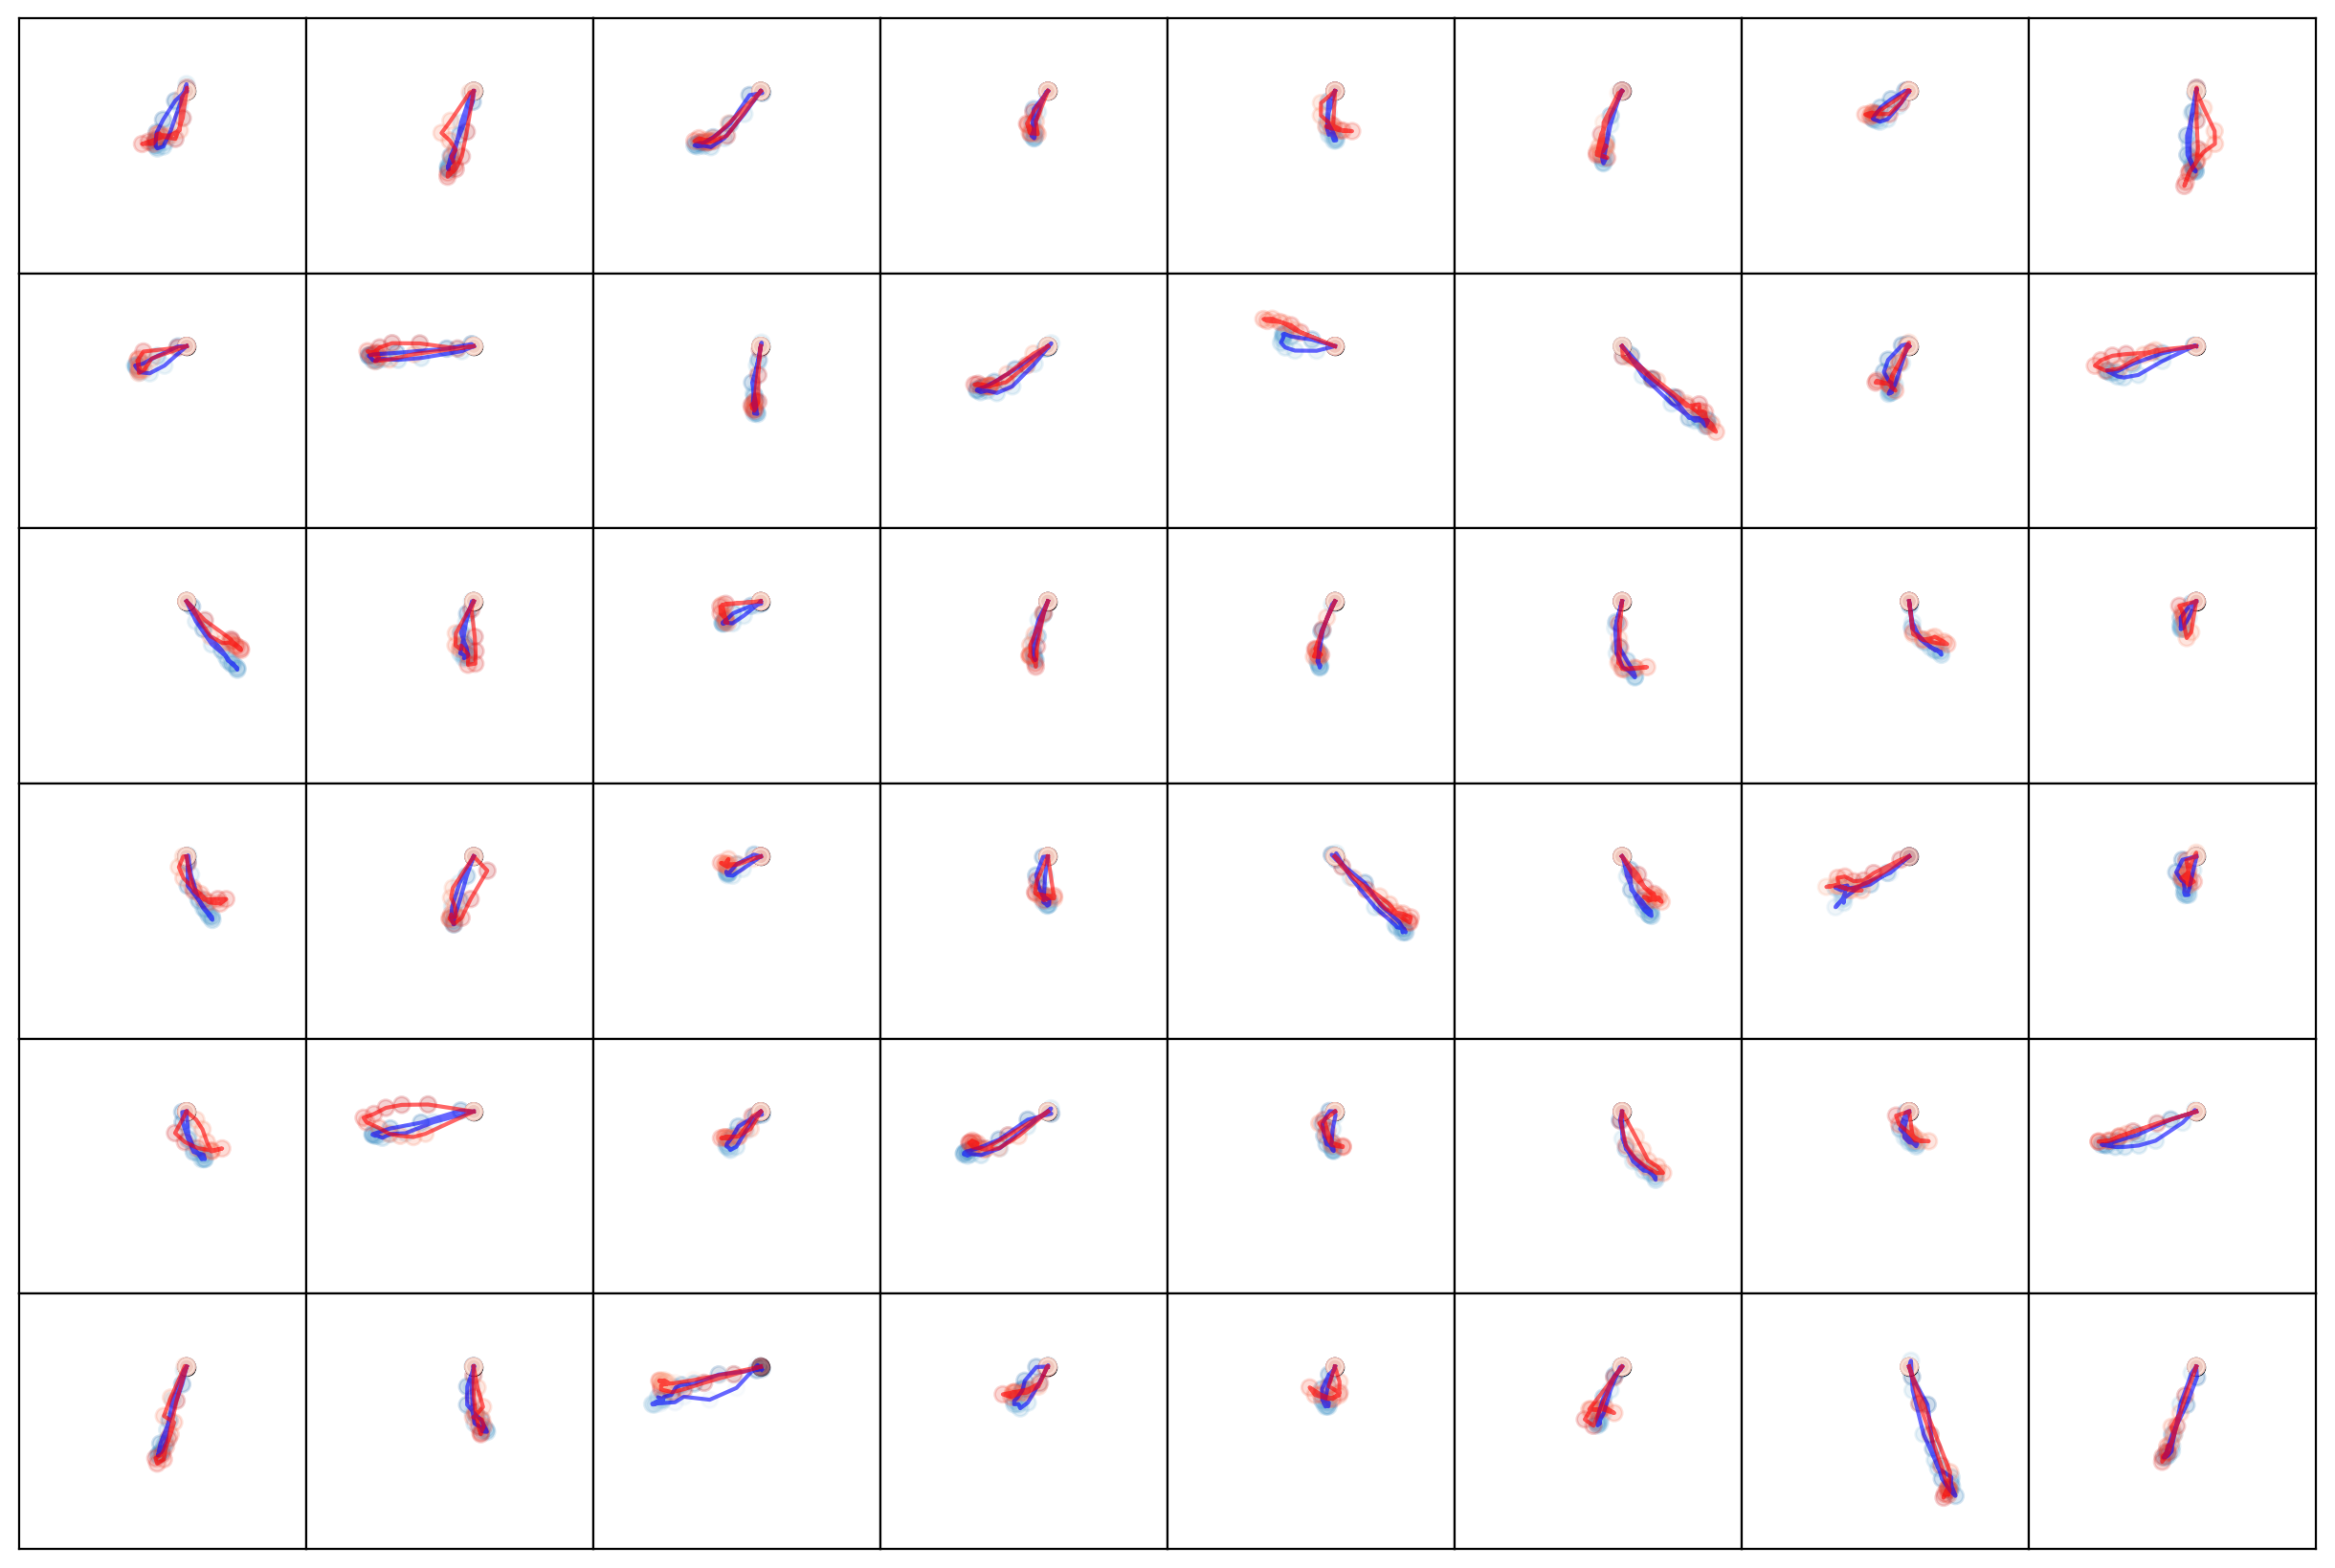

In [69]:
ind = torch.randperm(len(x_hat))[:48]
traj_sim = x_hat[ind,:, :].cpu().detach().numpy()
traj_real = real[ind,:, :].cpu().detach().numpy()

plt.figure(figsize = (12, 8), dpi=200)

for i in range(48):
    plt.subplot(6, 8, i+1)
    plt.scatter(0, 0, c="black")
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="blue", alpha=0.6)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r", alpha = 0.2)
    plt.plot(traj_real[i,0,:], traj_real[i,1,:], c="red", alpha=0.6)
    plt.scatter(traj_real[i,0,:], traj_real[i,1,:], 
                c=np.arange(padding), cmap="Reds_r", alpha =0.2)
    plt.tick_params(axis='both', left=False, top=False, right=False, bottom=False, labelleft=False, labeltop=False, labelright=False, labelbottom=False)

#    plt.axis('off')
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)
plt.subplots_adjust(left=0,
                    bottom=0,
                    right=1,
                    top=1,
                    wspace=0,
                    hspace=0)
plt.show()
plt.close()

# Generating trajectories from a grid for sensitivity analysis

In [63]:
nb = 100
mu3, mu1 = torch.meshgrid(torch.linspace(2,-2,  steps = 10), torch.linspace(-2,2,  steps = 10))
z = torch.concat([mu1.reshape(nb, 1), torch.zeros(nb, 1), mu3.reshape(nb, 1)], dim = 1).reshape(nb, nz, 1).repeat(12,1,1).to(device)
c = torch.tensor(np.append(np.cos(np.linspace(0,2,12, endpoint = False)*np.pi), 
                       np.sin(np.linspace(0,2,12, endpoint = False)*np.pi)), 
                 dtype=torch.float32).reshape(2, 12).t().reshape(12,2,1).repeat_interleave(nb,0).to(device)
with torch.no_grad():
    gen = G(z, c)
    


In [64]:
pd.DataFrame(data = {"mu1": z[:,0,0].repeat_interleave(24),
                     "mu2": z[:,2,0].repeat_interleave(24),
                     "cos_eta": c[:,0,0].repeat_interleave(24),
                     "sin_eta": c[:,1,0].repeat_interleave(24),
                     "h": np.tile(np.linspace(1,24,24), 1200),
                     "x": gen.permute(0,2,1).reshape(1200*24,2)[:,0],
                     "y": gen.permute(0,2,1).reshape(1200*24,2)[:,1]}).to_csv("../R_workflow/pydata/generated_traj_cvae3.csv")

# Exploring the tails of the latent space
Looking for trajectory where the L2 distance of the mean to the origin is superior to 4.

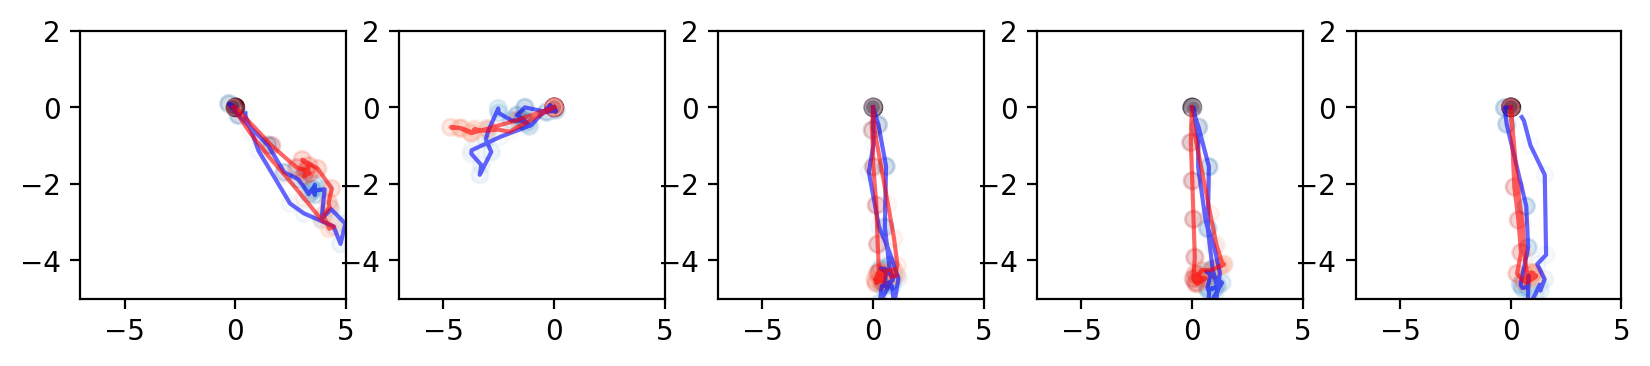

In [71]:
traj_sim = x_hat[mu.pow(2).sum(dim = 1).sqrt() > 4,:, :].cpu().detach().numpy()
traj_real = real[mu.pow(2).sum(dim = 1).sqrt() > 4,:, :].cpu().detach().numpy()

plt.figure(figsize = (12,8), dpi=200)

for i in range(5):
    plt.subplot(4, 6, i+1)
    plt.scatter(0, 0, c="black")
    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="blue", alpha=0.6)
    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
                c=np.arange(padding), cmap="Blues_r", alpha = 0.2)
    plt.plot(traj_real[i,0,:], traj_real[i,1,:], c="red", alpha=0.6)
    plt.scatter(traj_real[i,0,:], traj_real[i,1,:], 
                c=np.arange(padding), cmap="Reds_r", alpha =0.2)
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)
plt.show()
plt.close()

# Analyzing the spectral properties and some metrics of the generated data compare to the original data.

Warning: Our goal is not to generate perfect data but rather to obtain a latent space with nice properties, which can be analyzed.
The generated trajectories are oversmoothed, they are a deterministic output of a point in the latent space. 
We can obtain much better results using a GAN with a latent space of larger dimension.

In particular, we do not generate the uncommon trajectories where the boat stay at the harbour between 6am and noon.

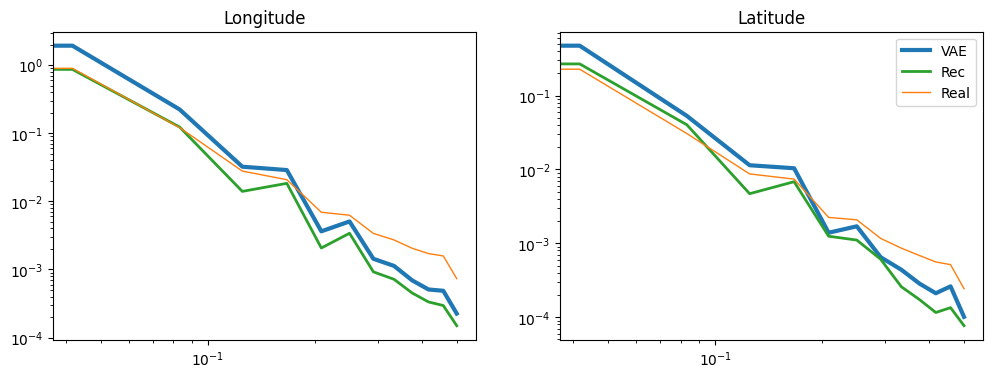

In [72]:
nb_traj = traj_std.shape[0]
#device = "cpu"
z = torch.randn((nb_traj, nz, 1)).to(device)
with torch.no_grad():
    generated = G(z, c = c_day)
    real = torch.tensor(traj_std[0:nb_traj, :, :], dtype=torch.float).to(device)
    with torch.no_grad():
        z, mu, logsig = E(real, c_day)
        x_hat = G(mu[:,:,None], c = c_day)
traj_sim = generated.cpu().detach().numpy()
traj_rec = x_hat.cpu().detach().numpy()


(x, lon_all, lat_all) = get_periodogram(traj_std[:,:,:])
(x, lon_sim, lat_sim) = get_periodogram(traj_sim)  # Generated at random from the prior N(0,1)
(x, lon_rec, lat_rec) = get_periodogram(traj_rec)  # Reconstructed from the mode

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.loglog(x, lon_sim, linewidth = 3, label = 'VAE', color ='tab:blue')
plt.loglog(x, lon_rec, linewidth = 2, label = 'Rec', color='tab:green')
plt.loglog(x, lon_all, linewidth = 1, label = 'Real', color='tab:orange')
plt.title('Longitude')
plt.subplot(1,2,2)
plt.loglog(x, lat_sim, linewidth = 3, label = 'VAE', color ='tab:blue')
plt.loglog(x, lat_rec, linewidth = 2, label = 'Rec', color='tab:green')
plt.loglog(x, lat_all, linewidth = 1, label = 'Real', color='tab:orange')
plt.title('Latitude')
plt.legend()
plt.show()
plt.close()



In [76]:
def coord2step(coord):
    step = np.sqrt(np.diff(coord[:,0,:])**2 + np.diff(coord[:,1,:])**2)
    step = np.append(np.zeros((coord.shape[0],1)), step, 1)
    direction = np.diff(np.arctan2(np.diff(coord[:,1,:]),np.diff(coord[:,0,:])))
    direction = np.append(np.zeros((coord.shape[0],2)), direction, 1)
    return np.stack([step*24, direction/2/np.pi], 1)

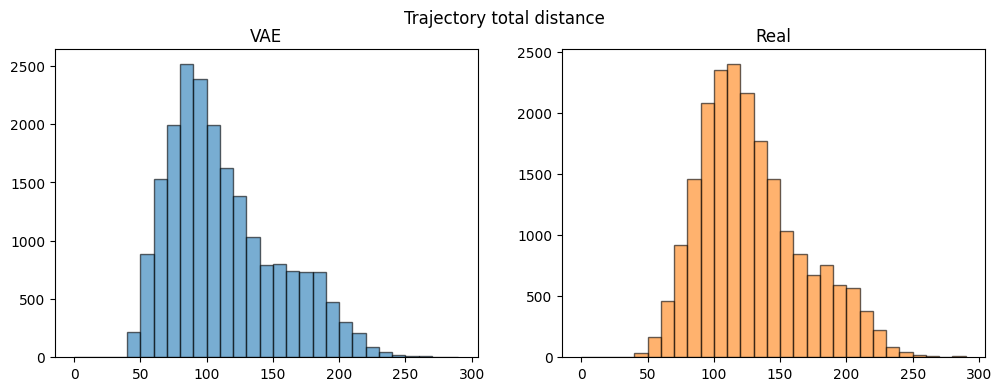

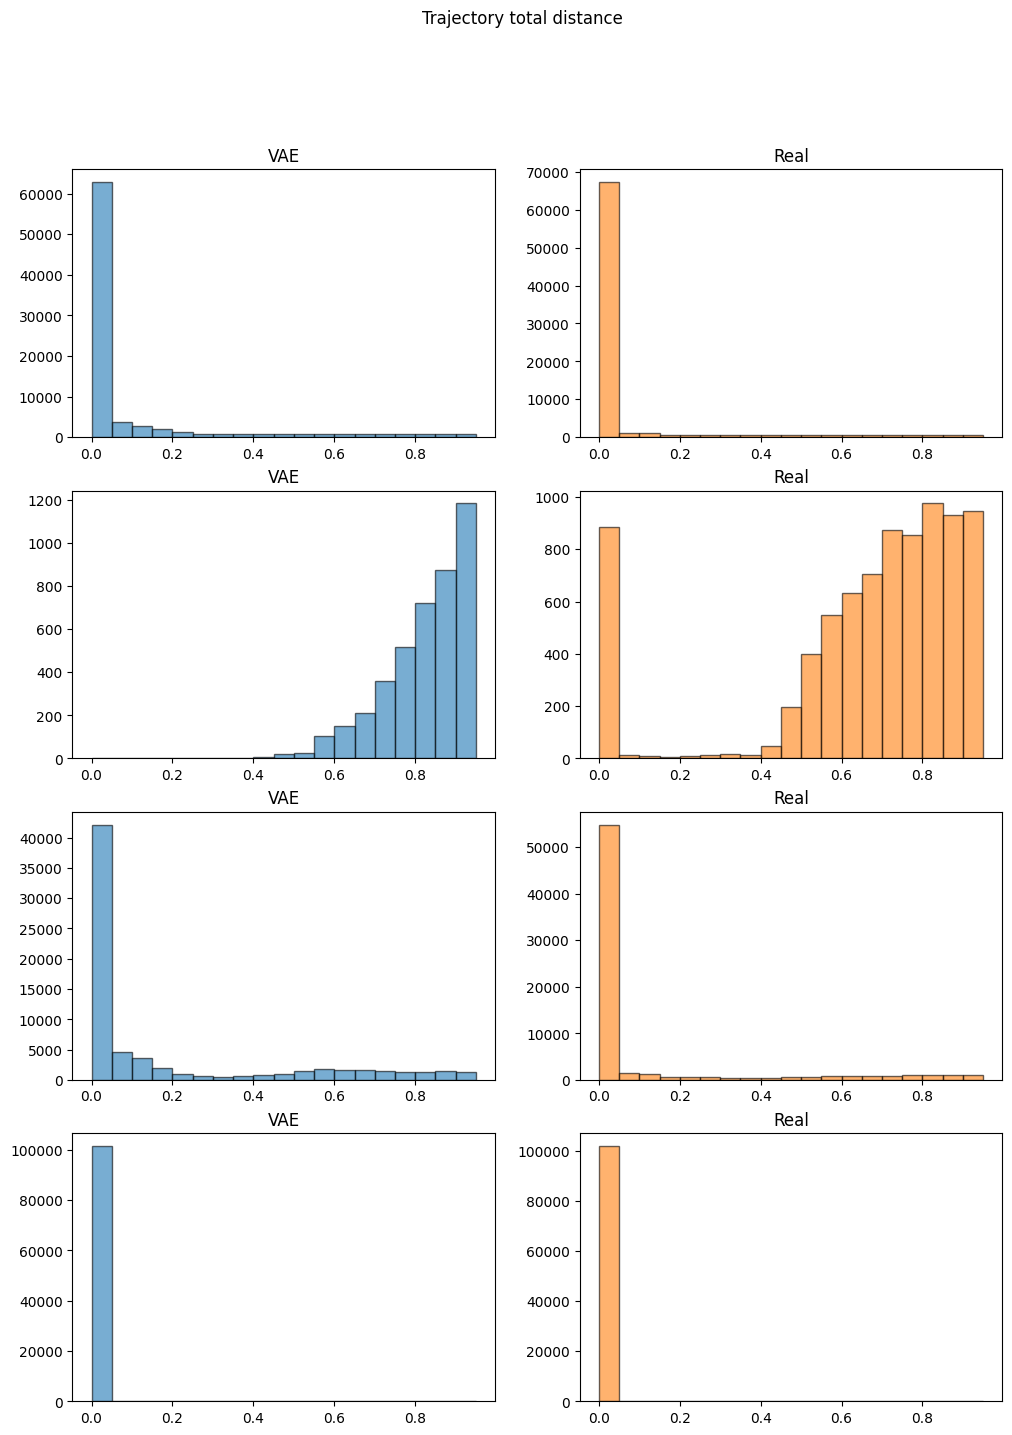

In [73]:

## Compare trajectories total distance

step_sim = coord2step(traj_sim)
step_all = coord2step(traj_std[:,:,:])
step_rec = coord2step(traj_rec)


plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(np.sum(step_rec[:,0,:], 1), bins = np.arange(0, 300, 10), alpha = 0.6, color='tab:blue', edgecolor = 'black')
plt.title('VAE')
plt.subplot(1,2,2)
plt.hist(np.sum(step_all[:,0,:], 1), bins = np.arange(0, 300, 10), alpha = 0.6, color='tab:orange', edgecolor = 'black')
plt.title('Real')
plt.suptitle('Trajectory total distance')
plt.show()

dist_std = np.sqrt(traj_std[:, 0, :]**2 + traj_std[:, 1, :]**2)
dist_rec = np.sqrt(traj_rec[:, 0, :]**2 + traj_rec[:, 1, :]**2)
plt.figure(figsize=(12,16))
for i in range(4):
    plt.subplot(4,2,(i*2)+1)
    plt.hist(dist_rec[:, (1+i*6):(6+i*6)].flatten(), color = 'tab:blue', bins = np.arange(0, 1, .05), alpha = 0.6, edgecolor = 'black')
    plt.title('VAE')
    plt.subplot(4,2,i*2+2)
    plt.hist(dist_std[:nb_traj, (1+i*6):(6+i*6)].flatten(), color = 'tab:orange', bins = np.arange(0, 1, .05), alpha = 0.6,  edgecolor = 'black')
    plt.title('Real')
plt.suptitle('Trajectory total distance')
plt.show()




<Axes: ylabel='Density'>

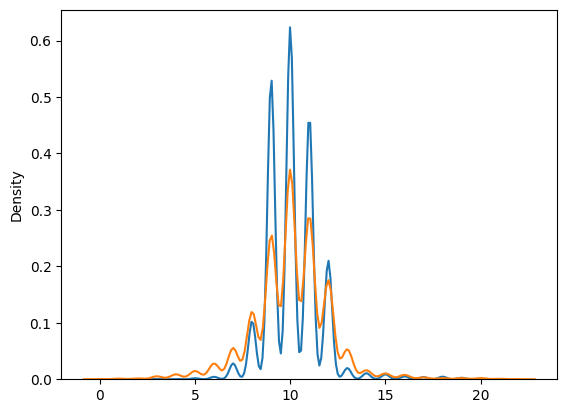

In [74]:
sns.kdeplot(np.sum(np.abs(traj_rec) > 0.5, axis=2).max(axis = 1), color='tab:blue')
sns.kdeplot(np.sum(np.abs(traj_std) > 0.5, axis=2).max(axis = 1), color='tab:orange')

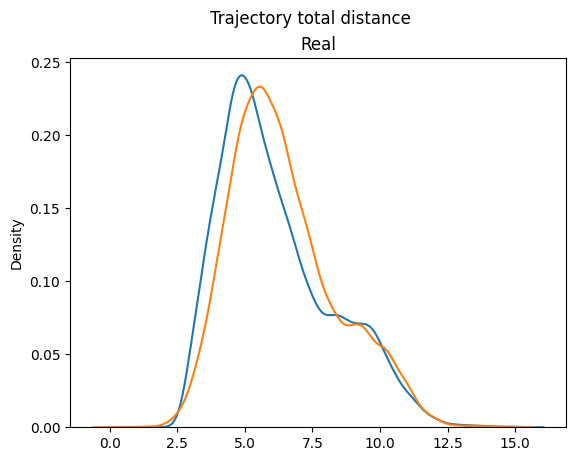

In [75]:
## Compare trajectories total distance

step_sim = coord2step(traj_sim)
step_all = coord2step(traj_std[:,:,:])
step_rec = coord2step(traj_rec)


#plt.figure(figsize=(12,4))
#plt.subplot(1,2,1)
sns.kdeplot(np.sqrt(np.diff(traj_rec[:,0,:])**2 + np.diff(traj_rec[:,1,:])**2).sum(axis = 1) + .5, color='tab:blue')
sns.kdeplot(np.sqrt(np.diff(traj_std[:,0,:])**2 + np.diff(traj_std[:,1,:])**2).sum(axis = 1), color='tab:orange')
#sns.kdeplot(np.sum(step_sim[:,0,:], 1), color='tab:green')
plt.title('VAE')
#plt.subplot(1,2,2)
#plt.hist(np.sum(step_all[:,0,:], 1), bins = np.arange(0, 300, 10), alpha = 0.6, color='tab:orange', edgecolor = 'black')
plt.title('Real')
plt.suptitle('Trajectory total distance')
plt.show()

## Move a trajectory in time
We encoder trajectories where an original trajectories is lagger in time.

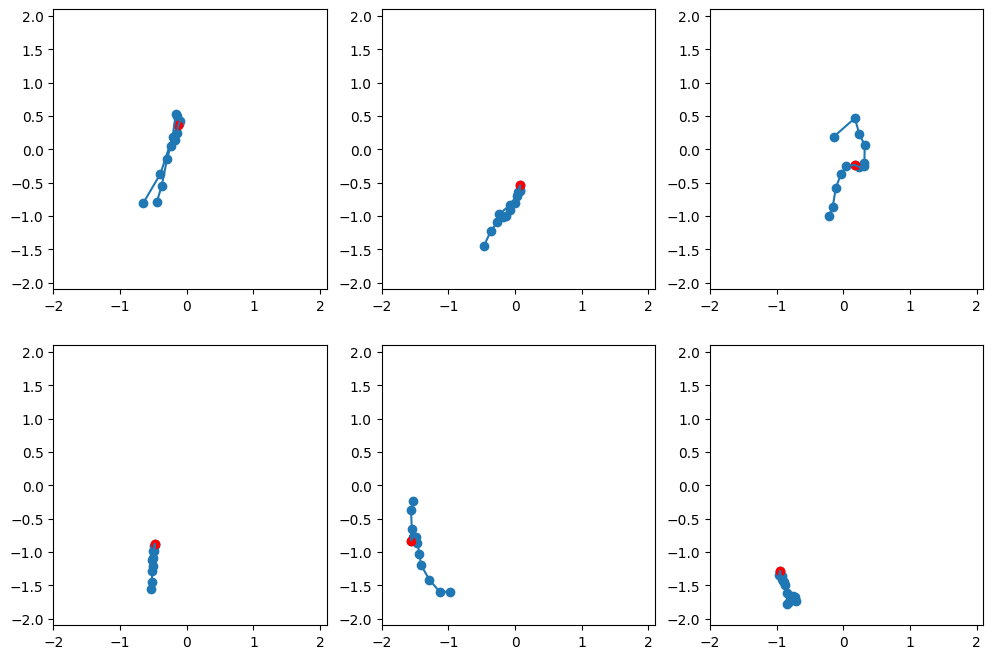

In [78]:
m = 1000
plt.figure(figsize = (12, 8))
for i,m  in enumerate(range(0, 3000, 500)):
    plt.subplot(2, 3, i+1)
    x_m = real[m:m+1, :, :].detach()
    t_min = min(torch.where(x_m != 0)[2])
    t_max = max(torch.where(x_m != 0)[2])
    l = t_max - t_min + 1
    nl = 23 - t_max + t_min

    mu_m1 = np.zeros((nl, 3))
    for i in range(nl):
        x_m1 = 0*x_m.detach()
        x_m1[:,:,0+i:l+i] = x_m[:,:,t_min:t_max+1]
        _, mu_m, _ = E(x_m1, c_day[m:m+1,:])
        mu_m1[i,:] = mu_m.detach().numpy()
    plt.plot(mu_m1[:,0], mu_m1[:,2])
    plt.scatter(mu_m1[:,0], mu_m1[:,2])
    plt.scatter(mu_m1[t_min,0], mu_m1[t_min,2], c = 'red')
    plt.xlim(min(-2, min(mu_m1[:,0]) - .1),max(2, max(mu_m1[:,0])) + .1)
    plt.ylim(min(-2, min(mu_m1[:,2])) - .1,max(2, max(mu_m1[:,2])) + .1)



And we compare it to other trajectories from the same day

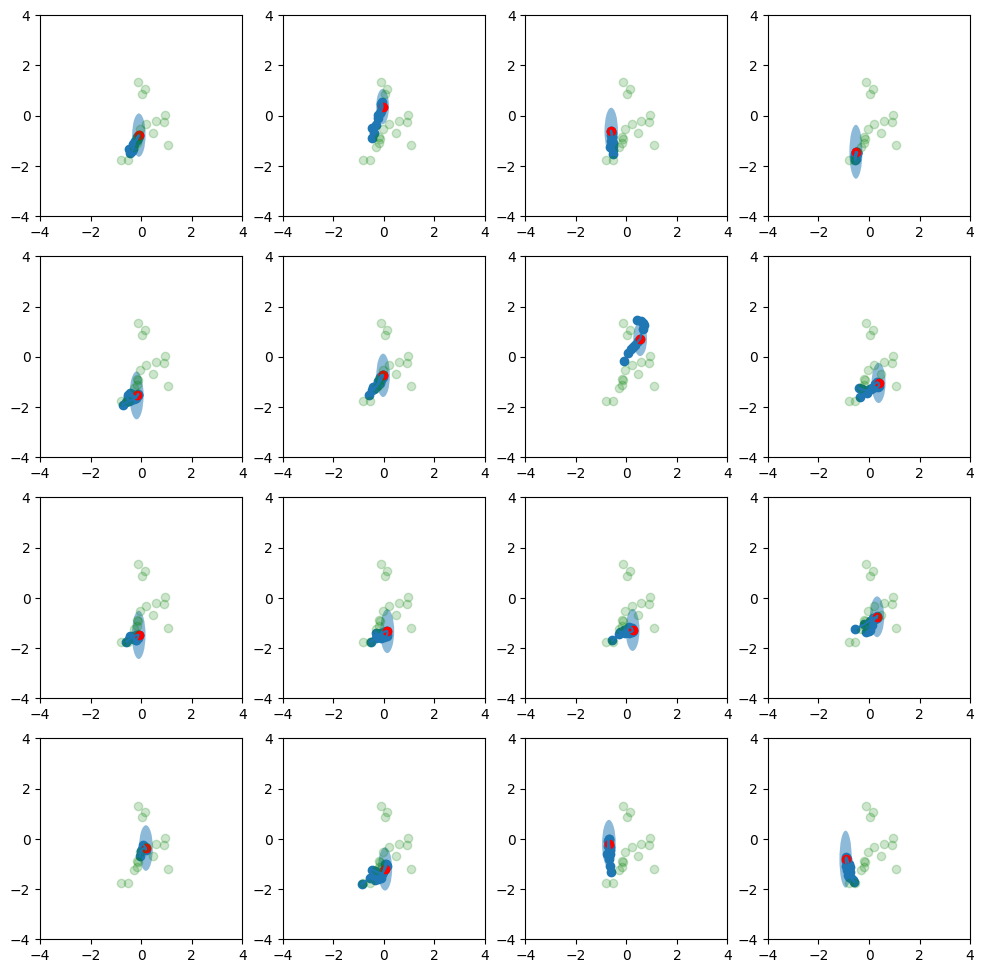

In [86]:

mu_20140210 = mu[np.array(maree_id.time == '2014-02-10'),:].detach().numpy()
plt.figure(figsize = (12, 12))
for i,m  in enumerate(maree_id[maree_id.time == "2014-02-10"].index):
    ax = plt.subplot(4, 4, i+1)
    x_m = real[m:m+1, :, :].detach()
    t_min = min(torch.where(x_m != 0)[2])
    t_max = max(torch.where(x_m != 0)[2])
    l = t_max - t_min + 1
    nl = 23 - t_max + t_min

    mu_m1 = np.zeros((nl, 3))
    sig_m1 = np.zeros((nl, 3))
    for i in range(nl):
        x_m1 = 0*x_m.detach()
        x_m1[:,:,0+i:l+i] = x_m[:,:,t_min:t_max+1]
        _, mu_m, sig_m = E(x_m1, c_day[m:m+1,:])
        mu_m1[i,:] = mu_m.detach().numpy()
        sig_m1[i,:] = sig_m.exp().detach().numpy()

    ax.plot(mu_m1[:,0], mu_m1[:,2])
    el = patches.Ellipse(xy=(mu_m1[t_min,0], mu_m1[t_min,2]), 
                    width = 4*np.sqrt(sig_m1[t_min,0]),
                    height = 4*np.sqrt(sig_m1[t_min,2]), alpha = 0.5)
    ax.add_artist(el)
    plt.scatter(mu_m1[:,0], mu_m1[:,2])
    plt.scatter(mu_m1[t_min,0], mu_m1[t_min,2], c = 'red')
    plt.scatter(mu_20140210[:,0], mu_20140210[:,2], c = 'green', alpha = .2)

    plt.xlim(-4, 4)
    plt.ylim(-4, 4)
#    plt.xlim(min(-2, min(mu_m1[:,0]) - .1),max(2, max(mu_m1[:,0])) + .1)
#    plt.ylim(min(-2, min(mu_m1[:,3])) - .1,max(2, max(mu_m1[:,3])) + .1)

### Plotting the distribution in the latent space for one day (a code reminder)

(-4.0, 4.0)

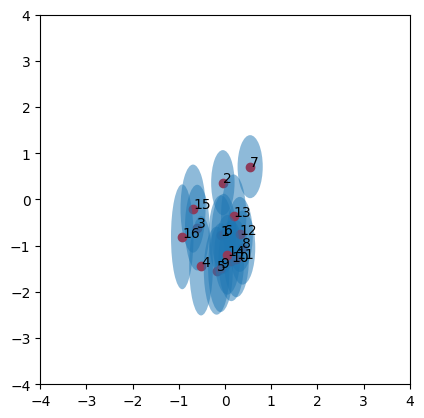

In [88]:

a = plt.subplot(111, aspect='equal')
for i,m  in enumerate(maree_id[maree_id.time == "2014-02-10"].index):
    x_m = real[m:m+1, :, :].detach()
#    t_min = min(torch.where(x_m != 0)[2])
#    t_max = max(torch.where(x_m != 0)[2])
#    l = t_max - t_min + 1
#    nl = 23 - t_max + t_min
    _, mu_m, sig_m = E(x_m, c_day[m:m+1,:])
    mu_m = mu_m.detach().numpy()
    sig_m = sig_m.exp().detach().numpy()

    a.scatter(mu_m[:,0], mu_m[:,2], c = 'red')
    el = patches.Ellipse(xy=(mu_m[:,0], mu_m[:,2]), 
                    width = 4*np.sqrt(sig_m[:,0]),
                    height = 4*np.sqrt(sig_m[:,2]), alpha = 0.5)
    a.add_artist(el)
    plt.text(mu_m[:,0], mu_m[:,2], s = str(i+1))
#    plt.scatter(mu_m1[:,0], mu_m1[:,3], c = 'red')

plt.xlim(-4, 4)
plt.ylim(-4, 4)

### Observations de differentes trajectoires

In [91]:
real_20150907 = real[np.array(maree_id.time == '2015-09-09'),:,:].detach().numpy()

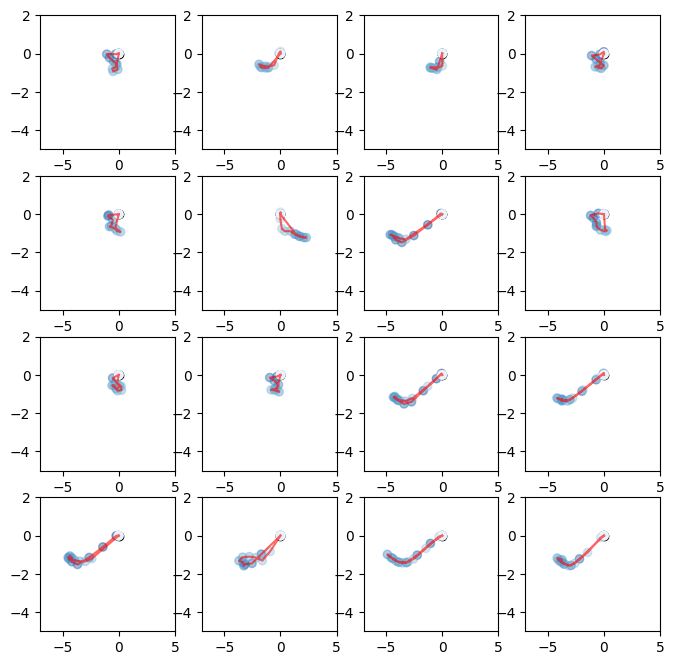

In [92]:
plt.figure(figsize=(8,8))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.scatter(0, 0, c="black")
#    plt.plot(traj_sim[i,0,:], traj_sim[i,1,:], c="blue", alpha=0.6)
#    plt.scatter(traj_sim[i,0,:], traj_sim[i,1,:], 
#                c=np.arange(padding), cmap="Blues_r", alpha = 0.2)
    plt.plot(real_20150907[i,0,:], real_20150907[i,1,:], c="red", alpha=0.6)
    plt.scatter(real_20150907[i,0,:], real_20150907[i,1,:], 
                c=np.arange(padding), cmap="Blues_r", alpha =0.4)
    plt.xlim(-7, 5)
    plt.ylim(-5, 2)
plt.show()
plt.close()

In [93]:
mu_20150907 = mu[np.array(maree_id.time == '2015-09-09')].detach().numpy()

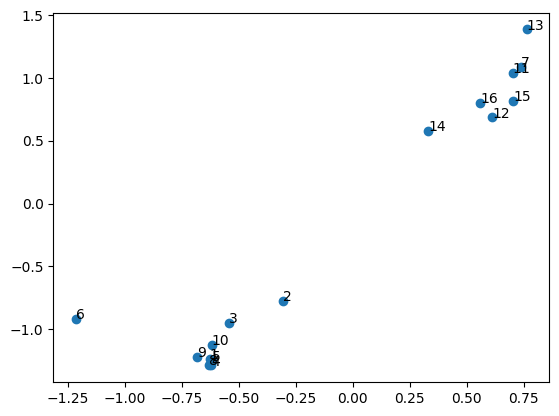

In [95]:
plt.scatter(x = mu_20150907[:,0],y =  mu_20150907[:,2] )
for i in range(16):
    plt.text(x = mu_20150907[i,0],y =  mu_20150907[i,2], s= str(i+1))
#plt.legend(loc="upper right", labels = np.arange(16))


## Analyse de jours extreme (20 juin 2014)

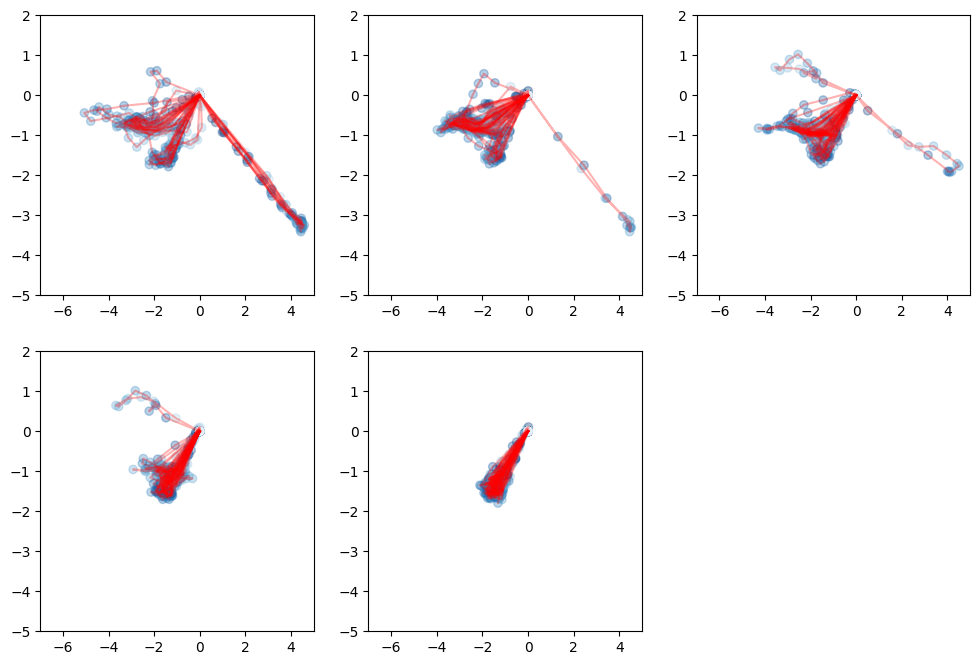

In [96]:
jour = ['2014-06-16', '2014-06-17', '2014-06-18', '2014-06-19', '2014-06-20']
plt.figure(figsize=(12, 8))
for j in range(5):
    my_traj = traj_std[ (maree_id.time == jour[j]),:,: ] 
    plt.subplot(2, 3, j+1)
    for i in range(my_traj.shape[0]):
        plt.plot(my_traj[i,0,:], my_traj[i,1,:], c="red", alpha=0.3)
        plt.scatter(my_traj[i,0,:], my_traj[i,1,:], 
                    c=np.arange(padding), cmap="Blues_r", alpha =0.3)
        plt.xlim(-7, 5)
        plt.ylim(-5, 2)

plt.show()
plt.close()